In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [66]:
#### INPUT PATH AND LOAD DATA
INPUT_FOLDER = 'tris\\fd_push_full_rod_dats'
r0_values = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 
             16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
k_values = [0.25]
seed = [1, 2, 3]


dfs = {}  # dfs[k][r0][seed] = dataframe

for k in k_values:
    k_tag = f"{int(round(k * 100)):03d}"   # 0.35 -> "035", 0.45 -> "045"
    dfs[k] = {}

    for r0 in r0_values:
        dfs[k][r0] = {}
        for s in seed:
            path = os.path.join(INPUT_FOLDER, f"obs_K_{k_tag}_r0_{r0}_seed_{s}.dat")

            dfs[k][r0][s] = pd.read_csv(
                path,
                sep=r"\s+",          
                header=None,
                names=["step", "dist", "force_mag", "hbond"]
            )

C:\Users\Tristan\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


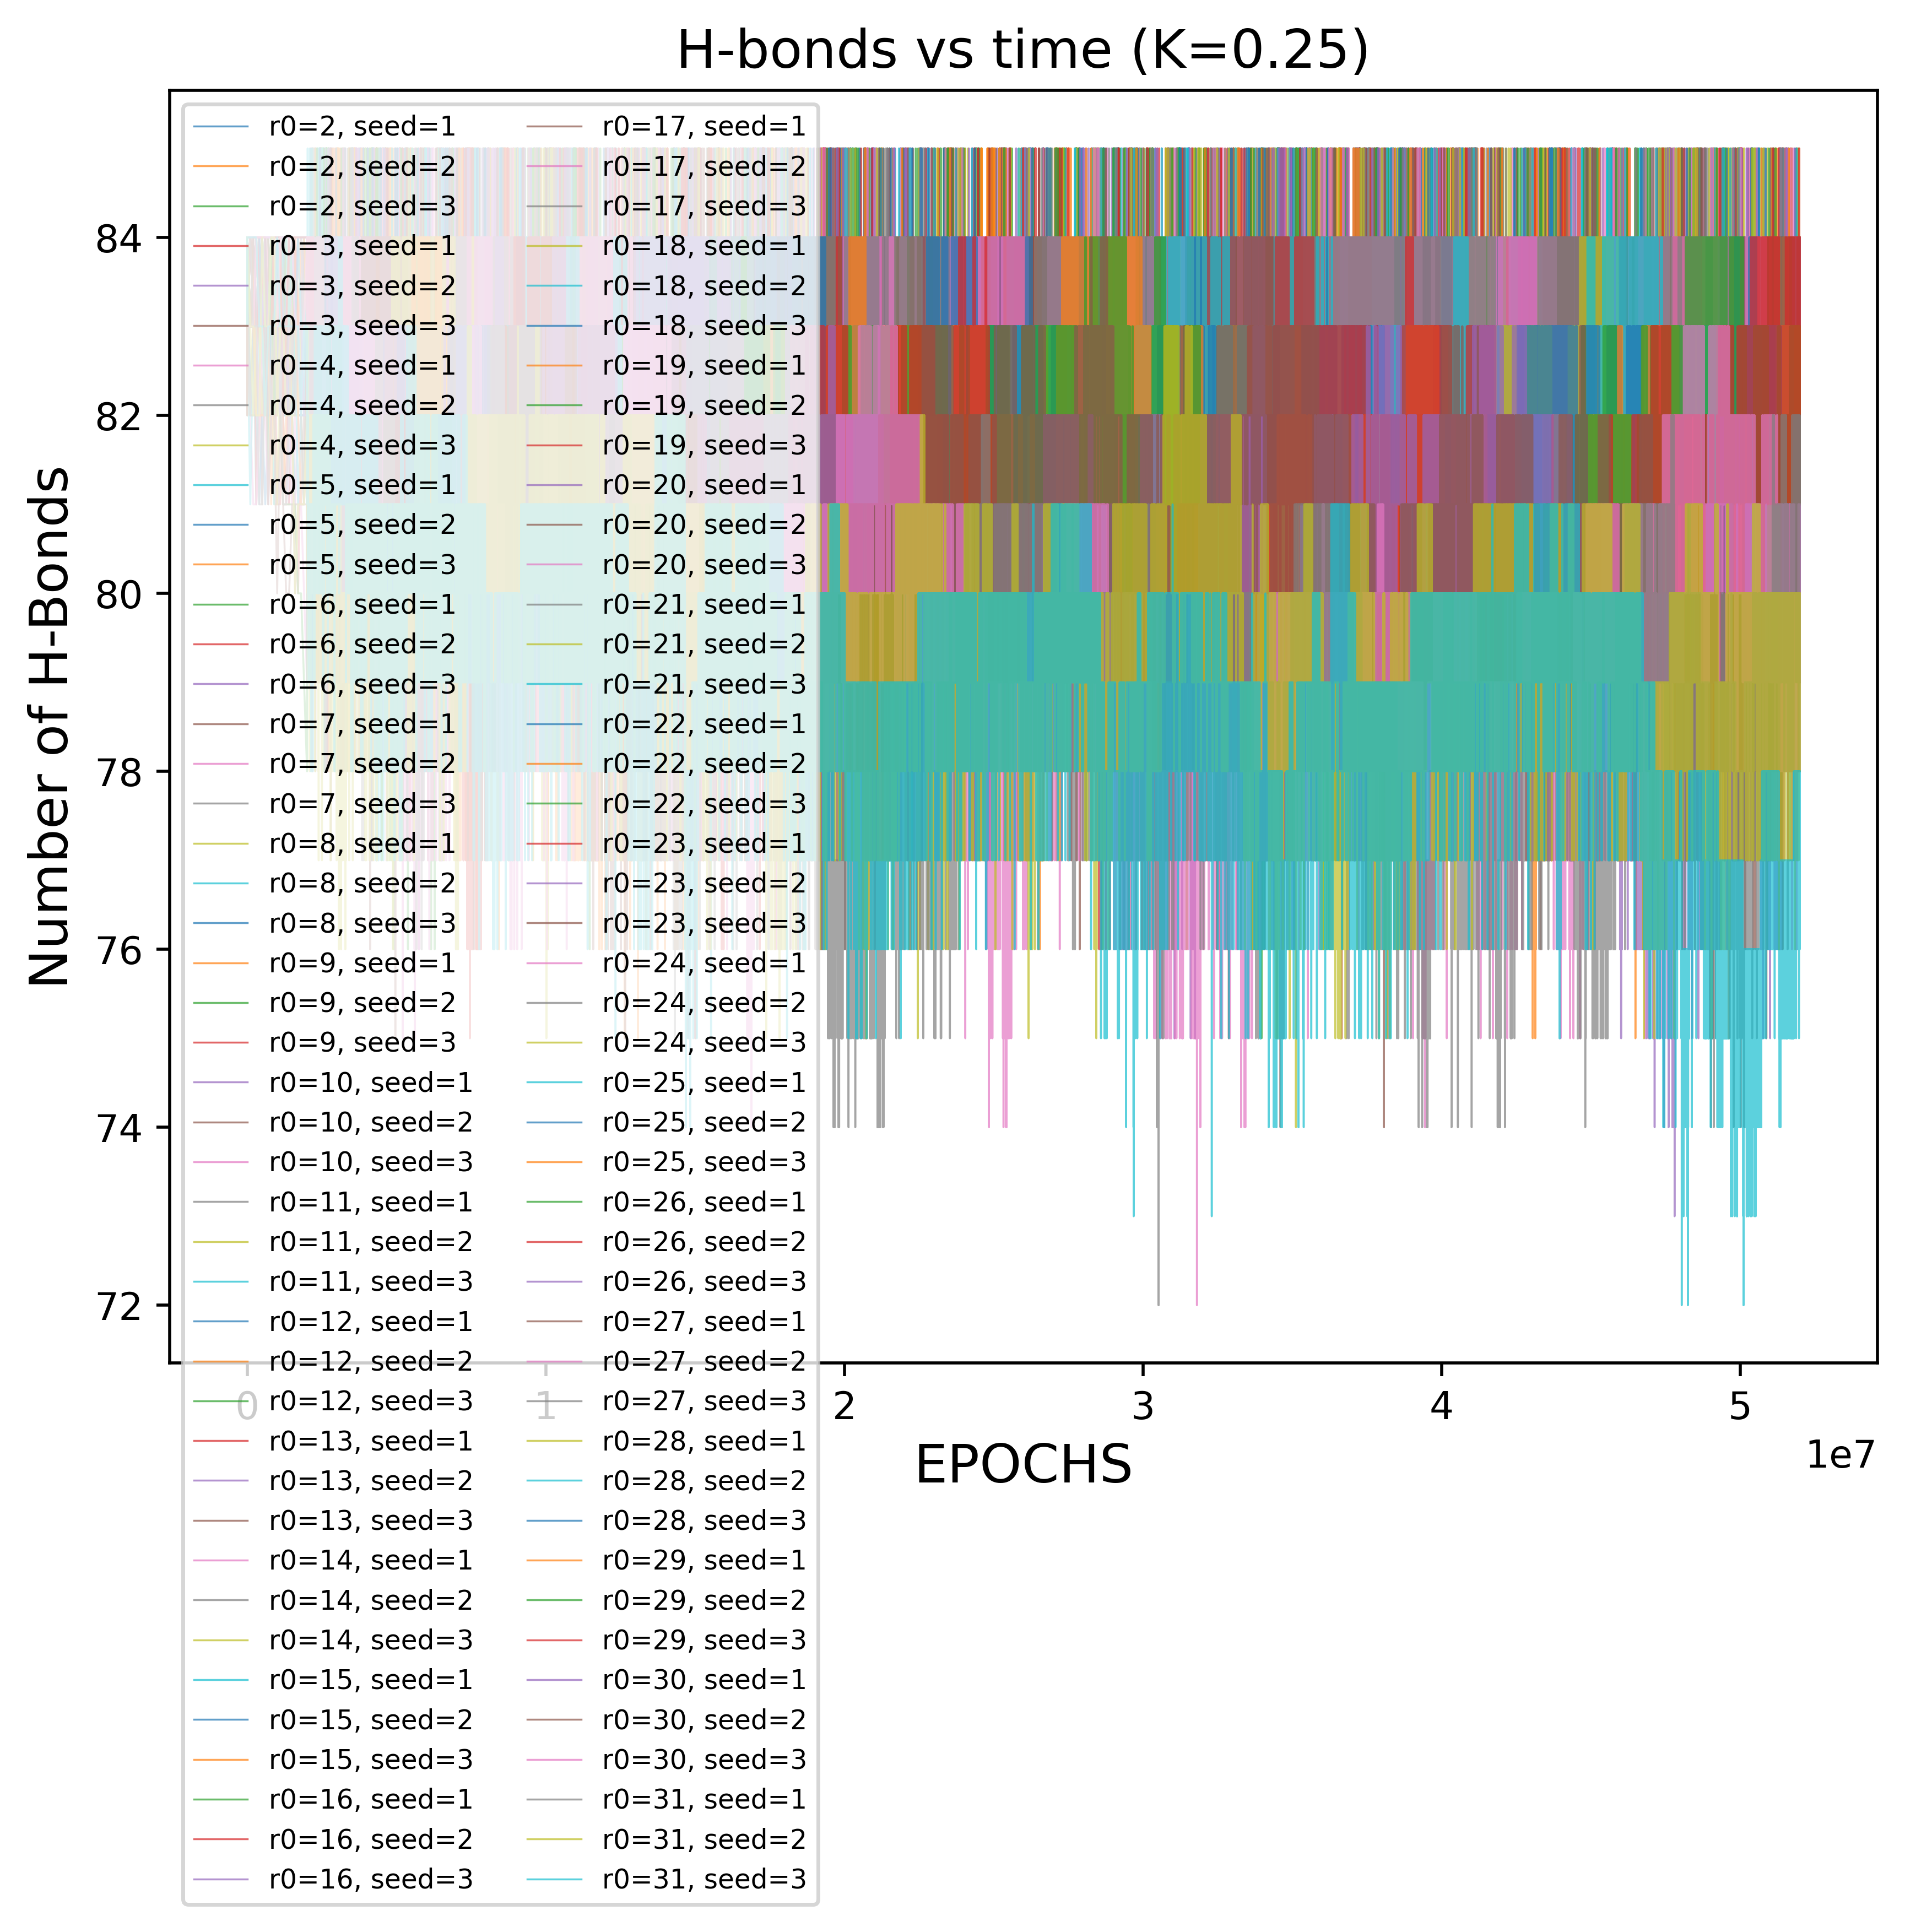

In [67]:
#### PLOTTING H-BONDS VS TIME FOR DIFFERENT r0 AND SEED VALUES

for k in k_values:
    fig, ax = plt.subplots(figsize=(8,6), dpi=500)

    if k not in dfs:
        continue

    for r0 in r0_values:
        if r0 not in dfs[k]:
            continue
        for s, df in dfs[k][r0].items():
            ax.plot(df["step"], df["hbond"],
                    alpha=0.7, linewidth=0.5,
                    label=f"r0={r0}, seed={s}")

    ax.set_title(f"H-bonds vs time (K={k})", fontsize=14)
    ax.set_xlabel("EPOCHS", fontsize=14)
    ax.set_ylabel("Number of H-Bonds", fontsize=14)

    # With many curves, legend can get huge; you can comment it out or shrink it:
    ax.legend(fontsize=7, ncol=2, frameon=True)

    plt.show()

In [68]:
def steady_cutoff_by_hbonds(df,
                            tail_frac=0.10,
                            band=3.0,
                            min_stay=100000,
                            ):
    """
    Returns cutoff step where steady state begins, based on hbond convergence.
    df must have columns: 'step', 'hbond' (sorted by step).
    """
    d = df[["step", "hbond"]].dropna().sort_values("step").reset_index(drop=True)
    n = len(d)
    if n == 0:
        return None

    tail_n = int(n * tail_frac)
    plateau = d["hbond"].iloc[-tail_n:].median()  # robust plateau estimate

    in_band = (d["hbond"] >= plateau - band) & (d["hbond"] <= plateau + band)

    # Find earliest index i such that stable is True for the next min_stay points
    stable_run = in_band.rolling(min_stay, min_periods=min_stay).sum() >= min_stay
    idx = stable_run.idxmax() if stable_run.any() else None

    if idx is None:
        # fallback: if never "stays", cut at start of tail window
        return int(d["step"].iloc[-tail_n])

    # rolling window marks the END of the first full stable block; shift back
    start_idx = max(0, idx - (min_stay - 1))
    return int(d["step"].iloc[start_idx])

C:\Users\Tristan\AppData\Local\Temp\ipykernel_10112\1614467290.py:47: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Tristan\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


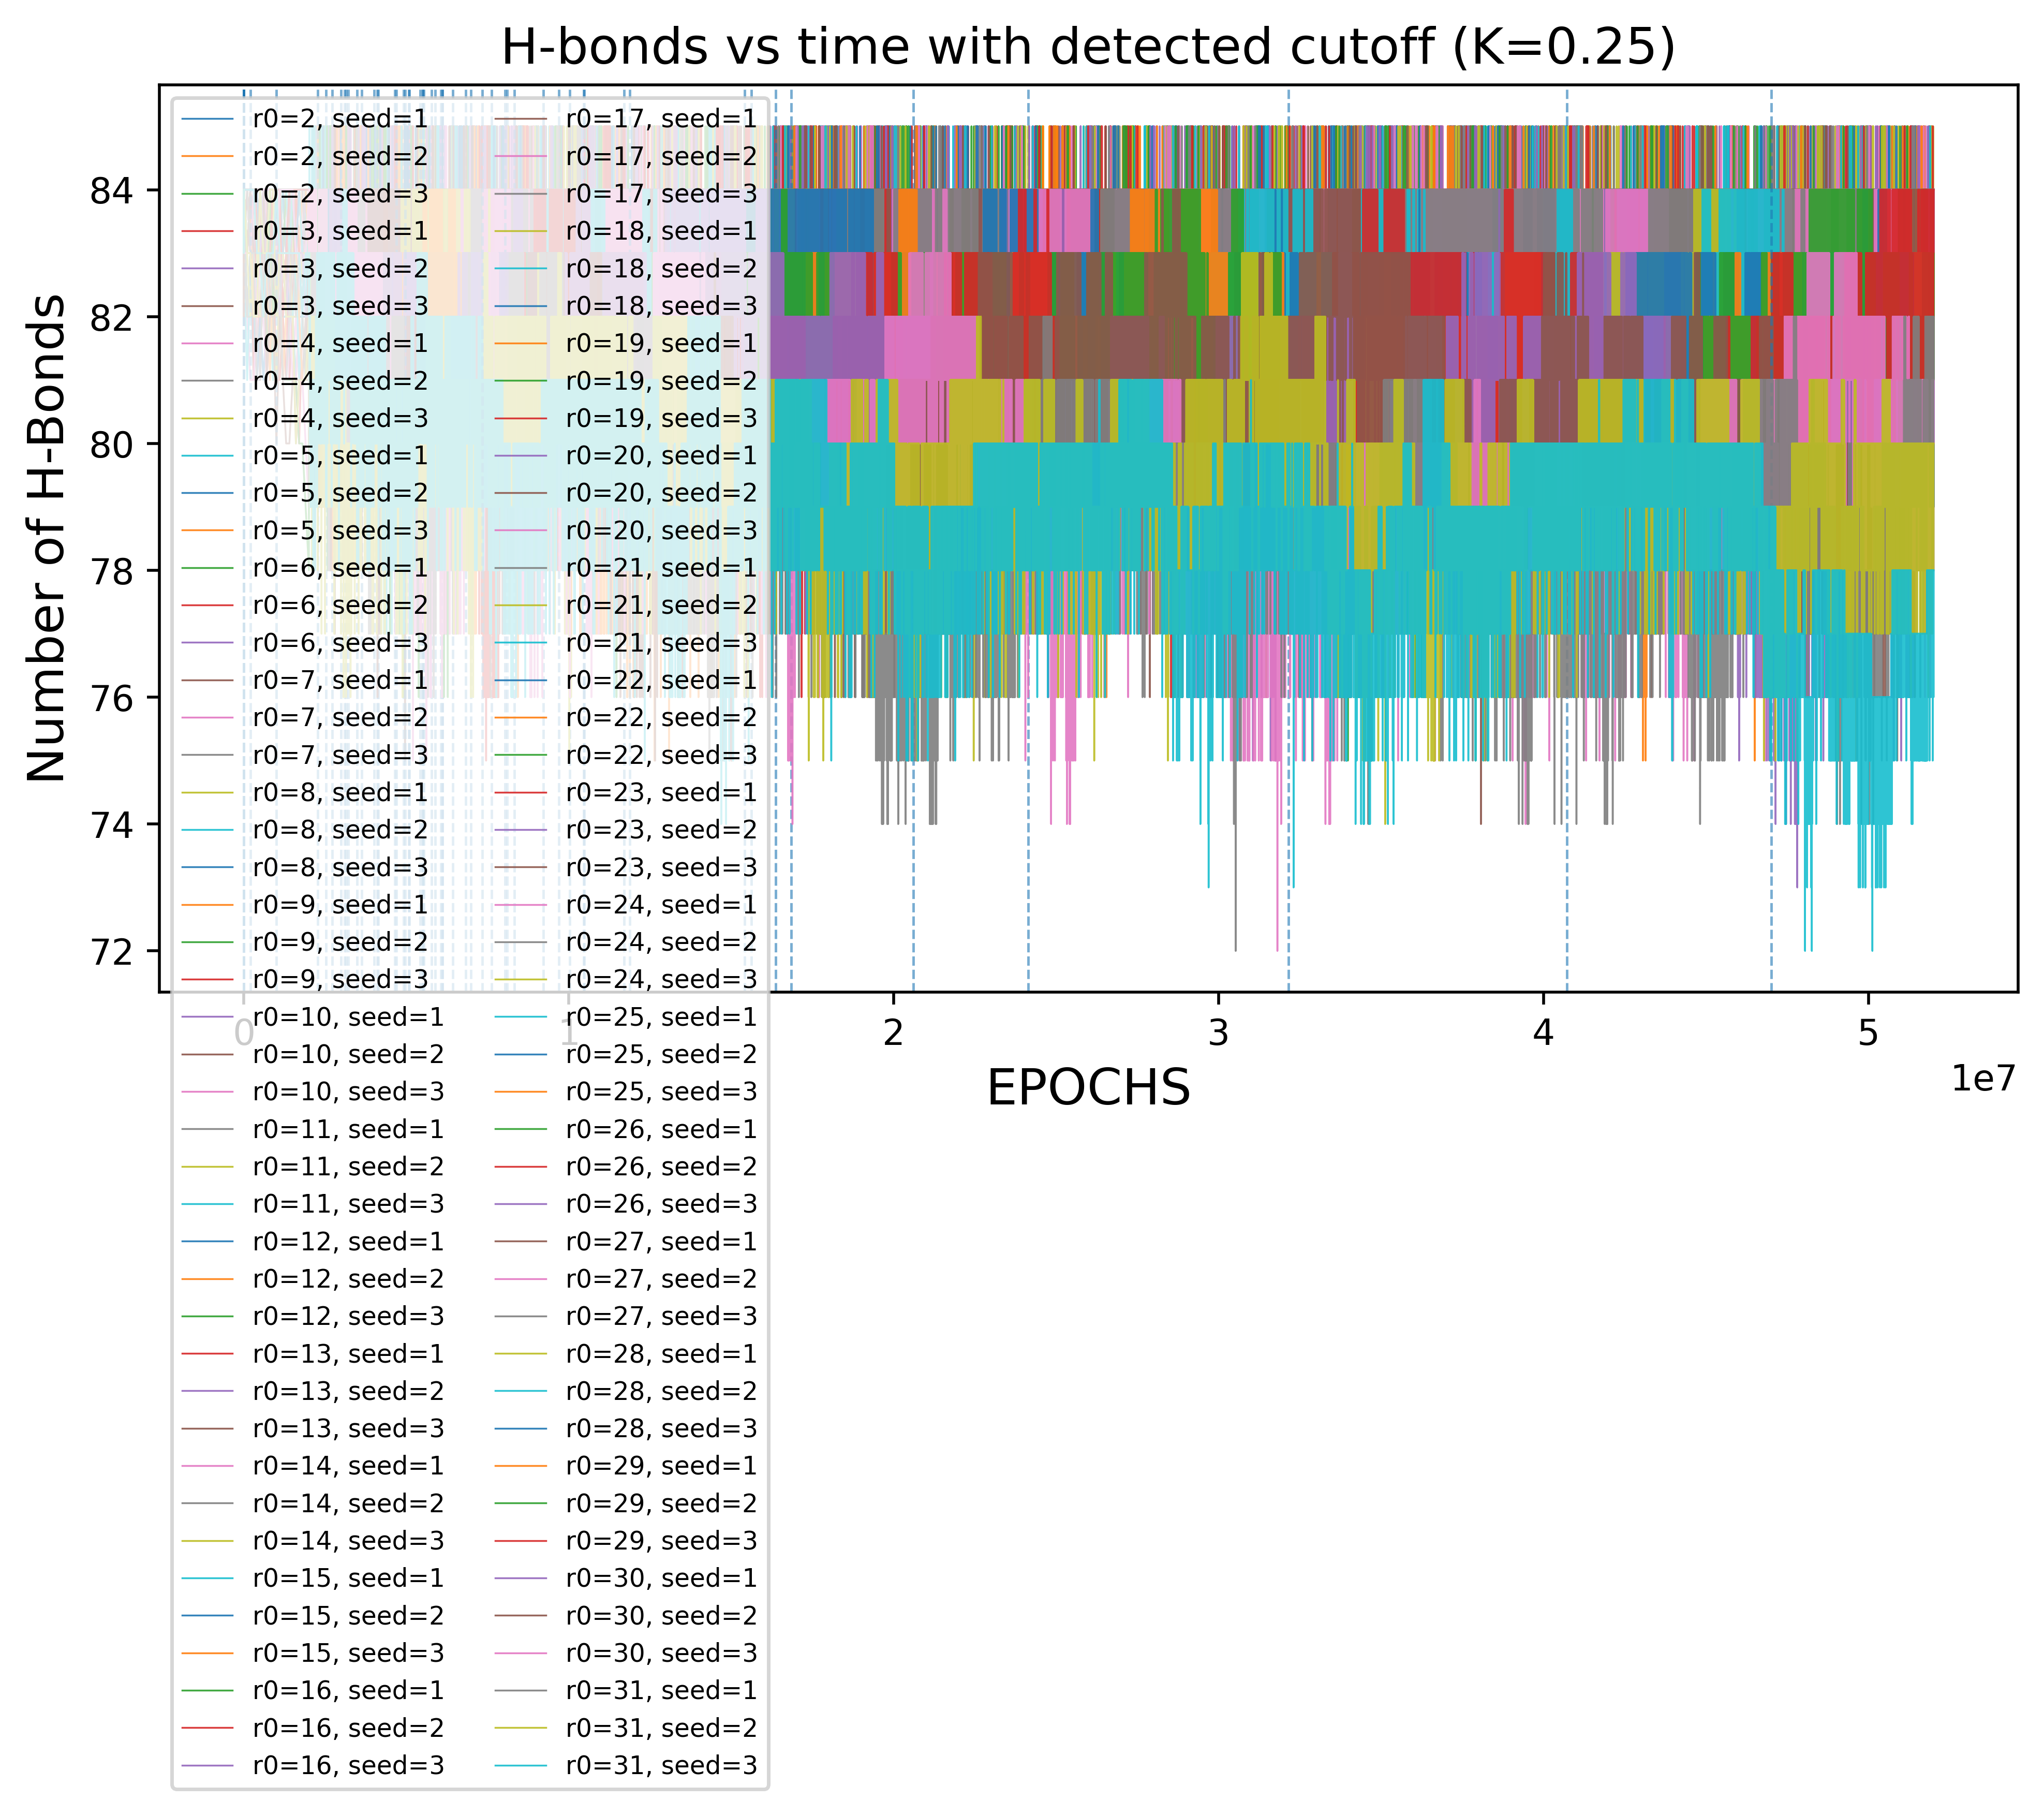

In [69]:
import matplotlib.pyplot as plt

source = dfs

# Parameters for cutoff detection
TAIL_FRAC = 0.10
BAND = 4.0
MIN_STAY_STEPS = 5000  # adjust (e.g. 1e6 or 2e6)

cutoffs = {}      # cutoffs[k][r0][seed] = cutoff_step
dfs_ss = {}       # steady-state cropped dfs: dfs_ss[k][r0][seed]

for k, by_r0 in source.items():
    cutoffs[k] = {}
    dfs_ss[k] = {}
    for r0, by_seed in by_r0.items():
        cutoffs[k][r0] = {}
        dfs_ss[k][r0] = {}
        for s, df in by_seed.items():
            c = steady_cutoff_by_hbonds(
                df,
                tail_frac=TAIL_FRAC,
                band=BAND,
                min_stay=MIN_STAY_STEPS,
            )
            cutoffs[k][r0][s] = c
            dfs_ss[k][r0][s] = df[df["step"] >= c].reset_index(drop=True)

# ---- Plot hbonds time series with vertical cutoff lines (one figure per k) ----
for k, by_r0 in source.items():
    fig, ax = plt.subplots(figsize=(8, 6), dpi=500)

    for r0, by_seed in by_r0.items():
        for s, df in by_seed.items():
            ax.plot(df["step"], df["hbond"], linewidth=0.5, alpha=0.9, label=f"r0={r0}, seed={s}")

            c = cutoffs[k][r0][s]
            ax.axvline(c, linestyle="--", linewidth=0.7, alpha=0.6)

    ax.set_title(f"H-bonds vs time with detected cutoff (K={k})", fontsize=14)
    ax.set_xlabel("EPOCHS", fontsize=14)
    ax.set_ylabel("Number of H-Bonds", fontsize=14)

    
    ax.legend(fontsize=7, ncol=2, frameon=True)

    plt.tight_layout()
    plt.show()

In [70]:
#### BASIC STATISTICS OF STEADY STATE REGION
import numpy as np
import pandas as pd

stats_data = []
for k, by_r0 in dfs_ss.items():
    for r0 in r0_values:
        if r0 not in by_r0:
            continue
        for s, df in by_r0[r0].items():

            # signed force: +|F| if dist > r0, -|F| if dist < r0
            # np.sign gives -1, 0, +1; equality -> 0 (force becomes 0 at exact r0)
            signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

            stats_data.append({
                "k": k,
                "r_0": float(r0),
                "seed": int(s),

                "F mean": signed_force.mean(),
                "F std": signed_force.std(ddof=0),

                "|F| mean": df["force_mag"].mean(),
                "|F| std": df["force_mag"].std(ddof=0),

                "dist mean": df["dist"].mean(),
                "dist std": df["dist"].std(ddof=0),
                "hbonds mean": df["hbond"].mean(),
            })

stats_df = pd.DataFrame(stats_data).sort_values(["k", "r_0", "seed"])
print(stats_df)

       k   r_0  seed    F mean     F std  |F| mean   |F| std  dist mean  \
0   0.25   2.0     1  0.194603  0.147770  0.206744  0.130243   2.778414   
1   0.25   2.0     2  0.208027  0.163719  0.218379  0.149632   2.832109   
2   0.25   2.0     3  0.200530  0.162687  0.211668  0.147906   2.802122   
3   0.25   3.0     1  0.186921  0.165761  0.203185  0.145369   3.747685   
4   0.25   3.0     2  0.169161  0.168840  0.191204  0.143399   3.676643   
..   ...   ...   ...       ...       ...       ...       ...        ...   
85  0.25  30.0     2 -0.367792  0.154578  0.368516  0.152842  28.528834   
86  0.25  30.0     3 -0.373066  0.151180  0.373339  0.150505  28.507735   
87  0.25  31.0     1 -0.360355  0.160664  0.361504  0.158061  29.558581   
88  0.25  31.0     2 -0.370109  0.149220  0.370723  0.147688  29.519562   
89  0.25  31.0     3 -0.334593  0.154038  0.336431  0.149981  29.661627   

    dist std  hbonds mean  
0   0.591078    82.948736  
1   0.654877    83.073315  
2   0.650749   

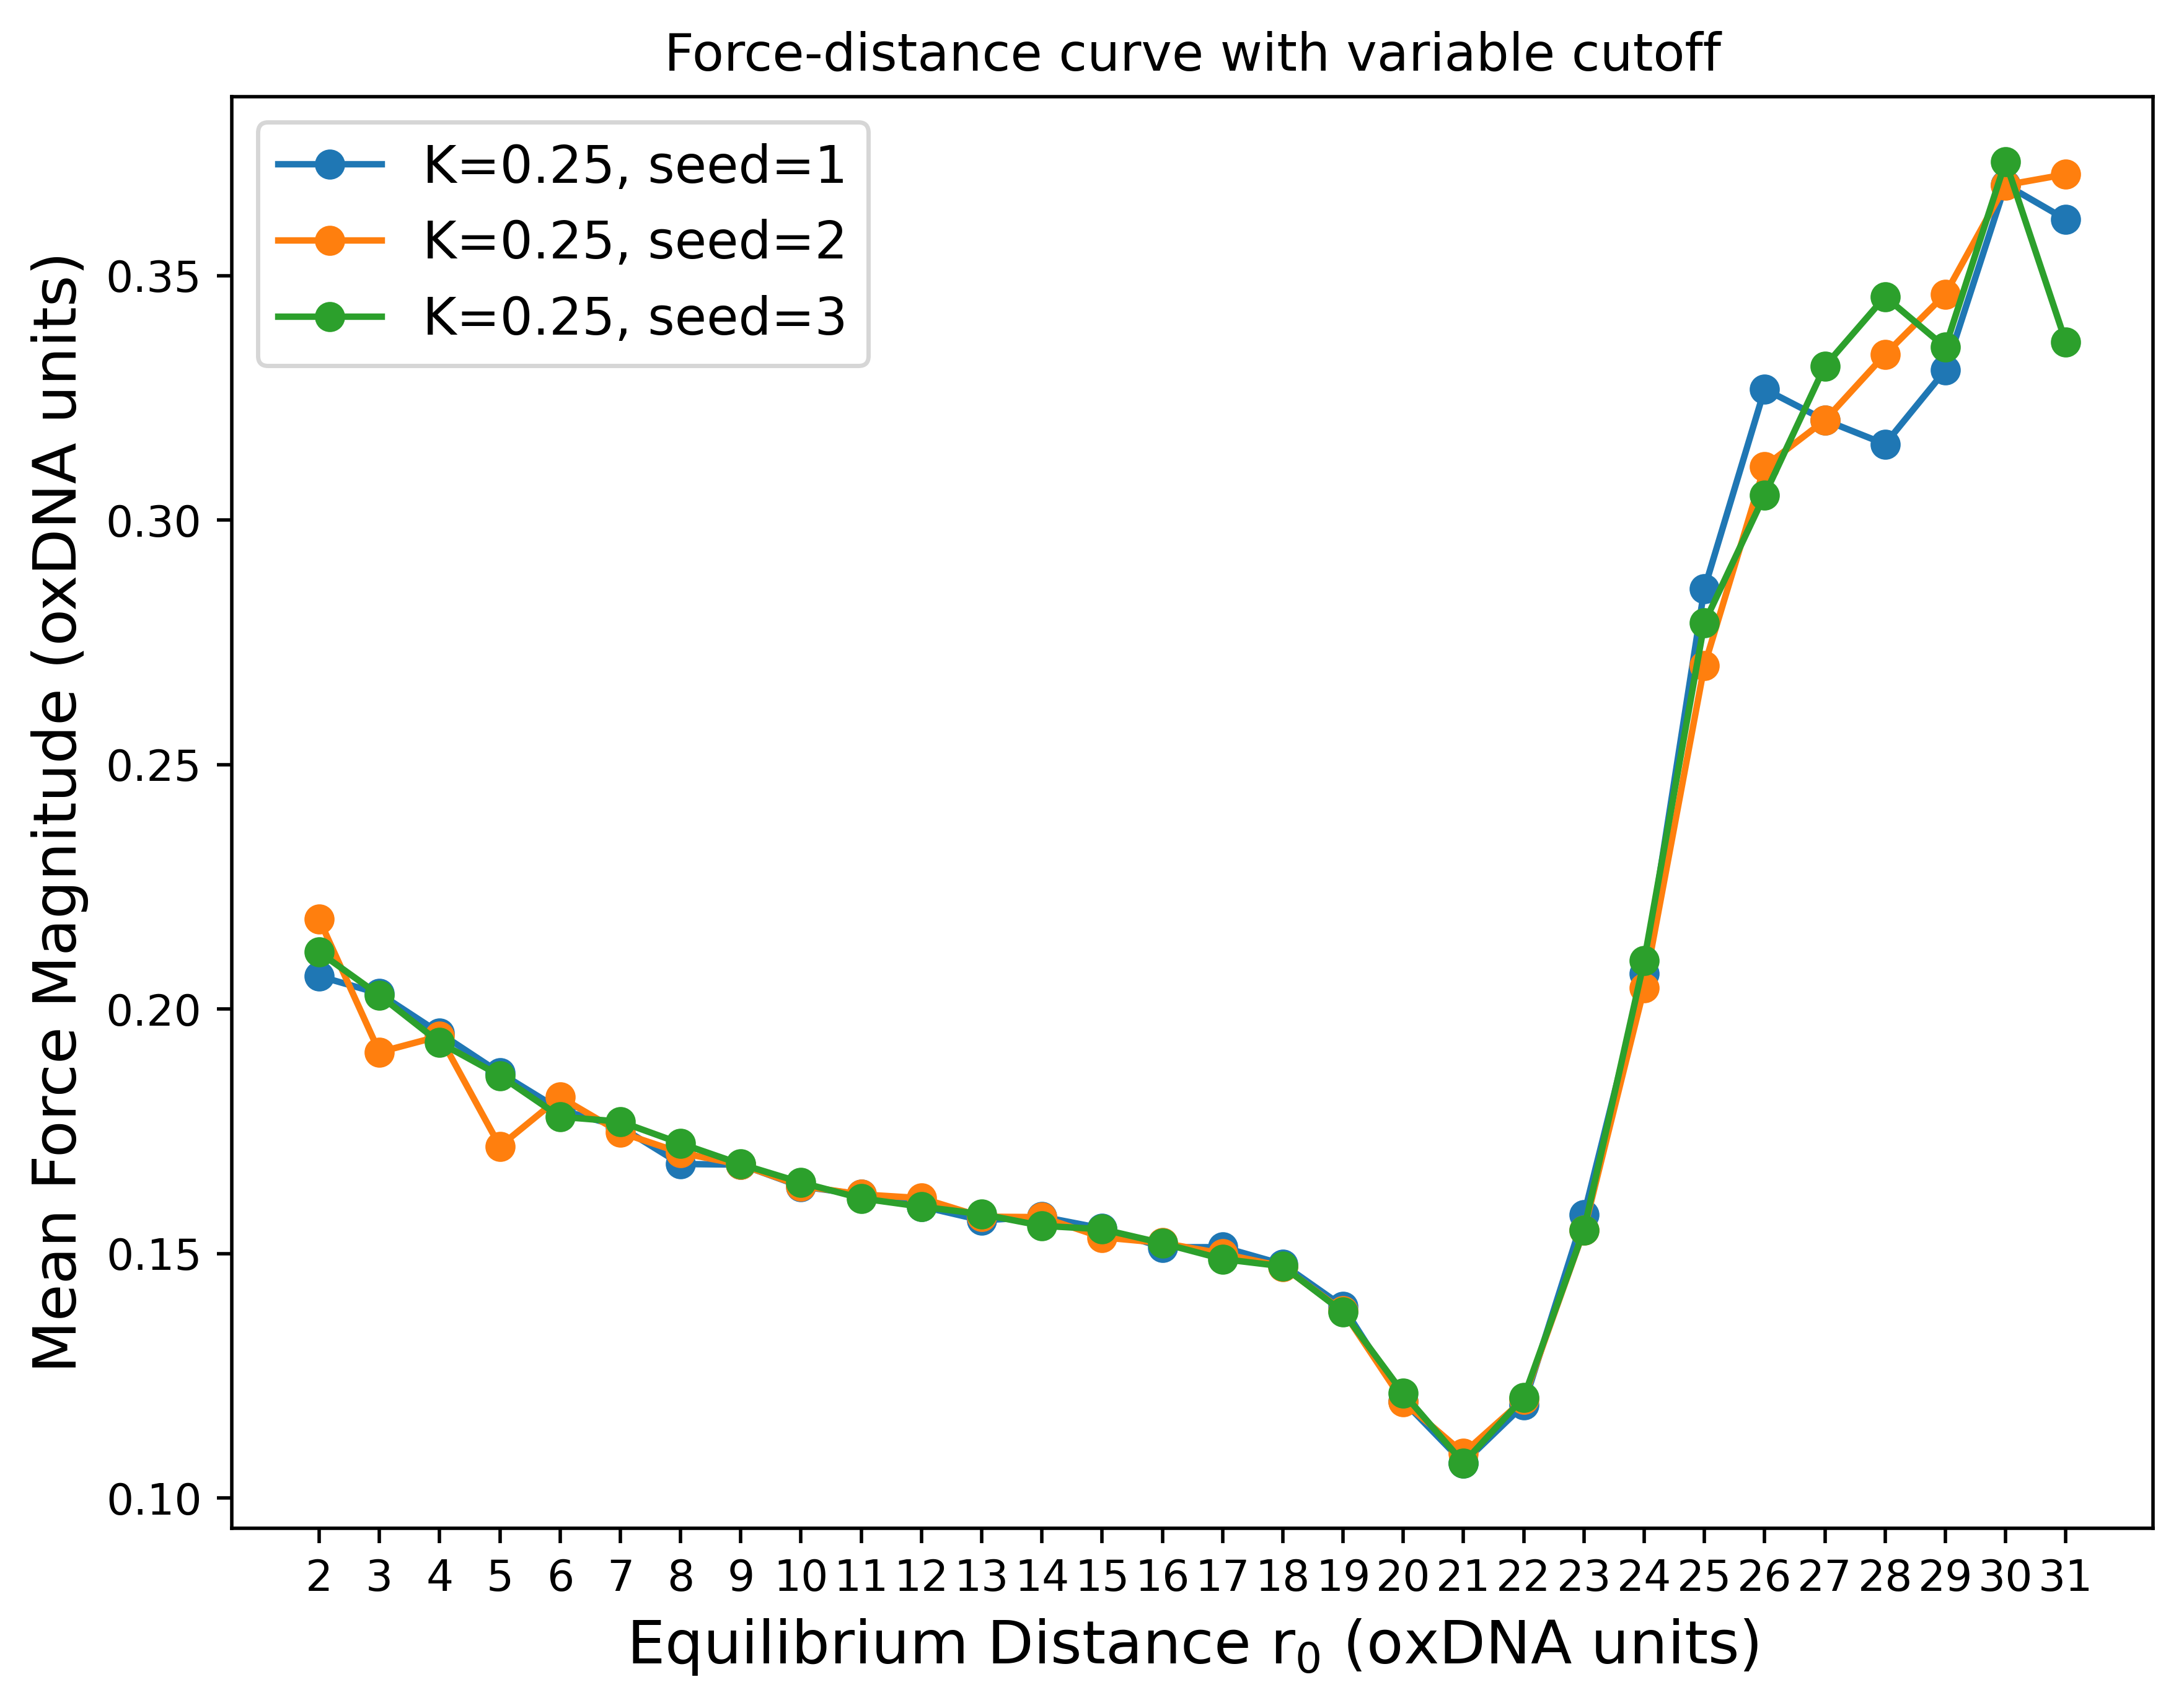

In [71]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        ax.plot(sub["r_0"], sub["|F| mean"], marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("Mean Force Magnitude (oxDNA units)", fontsize=14)
ax.set_title("Force-distance curve with variable cutoff")
ax.legend(fontsize=12)

plt.show()

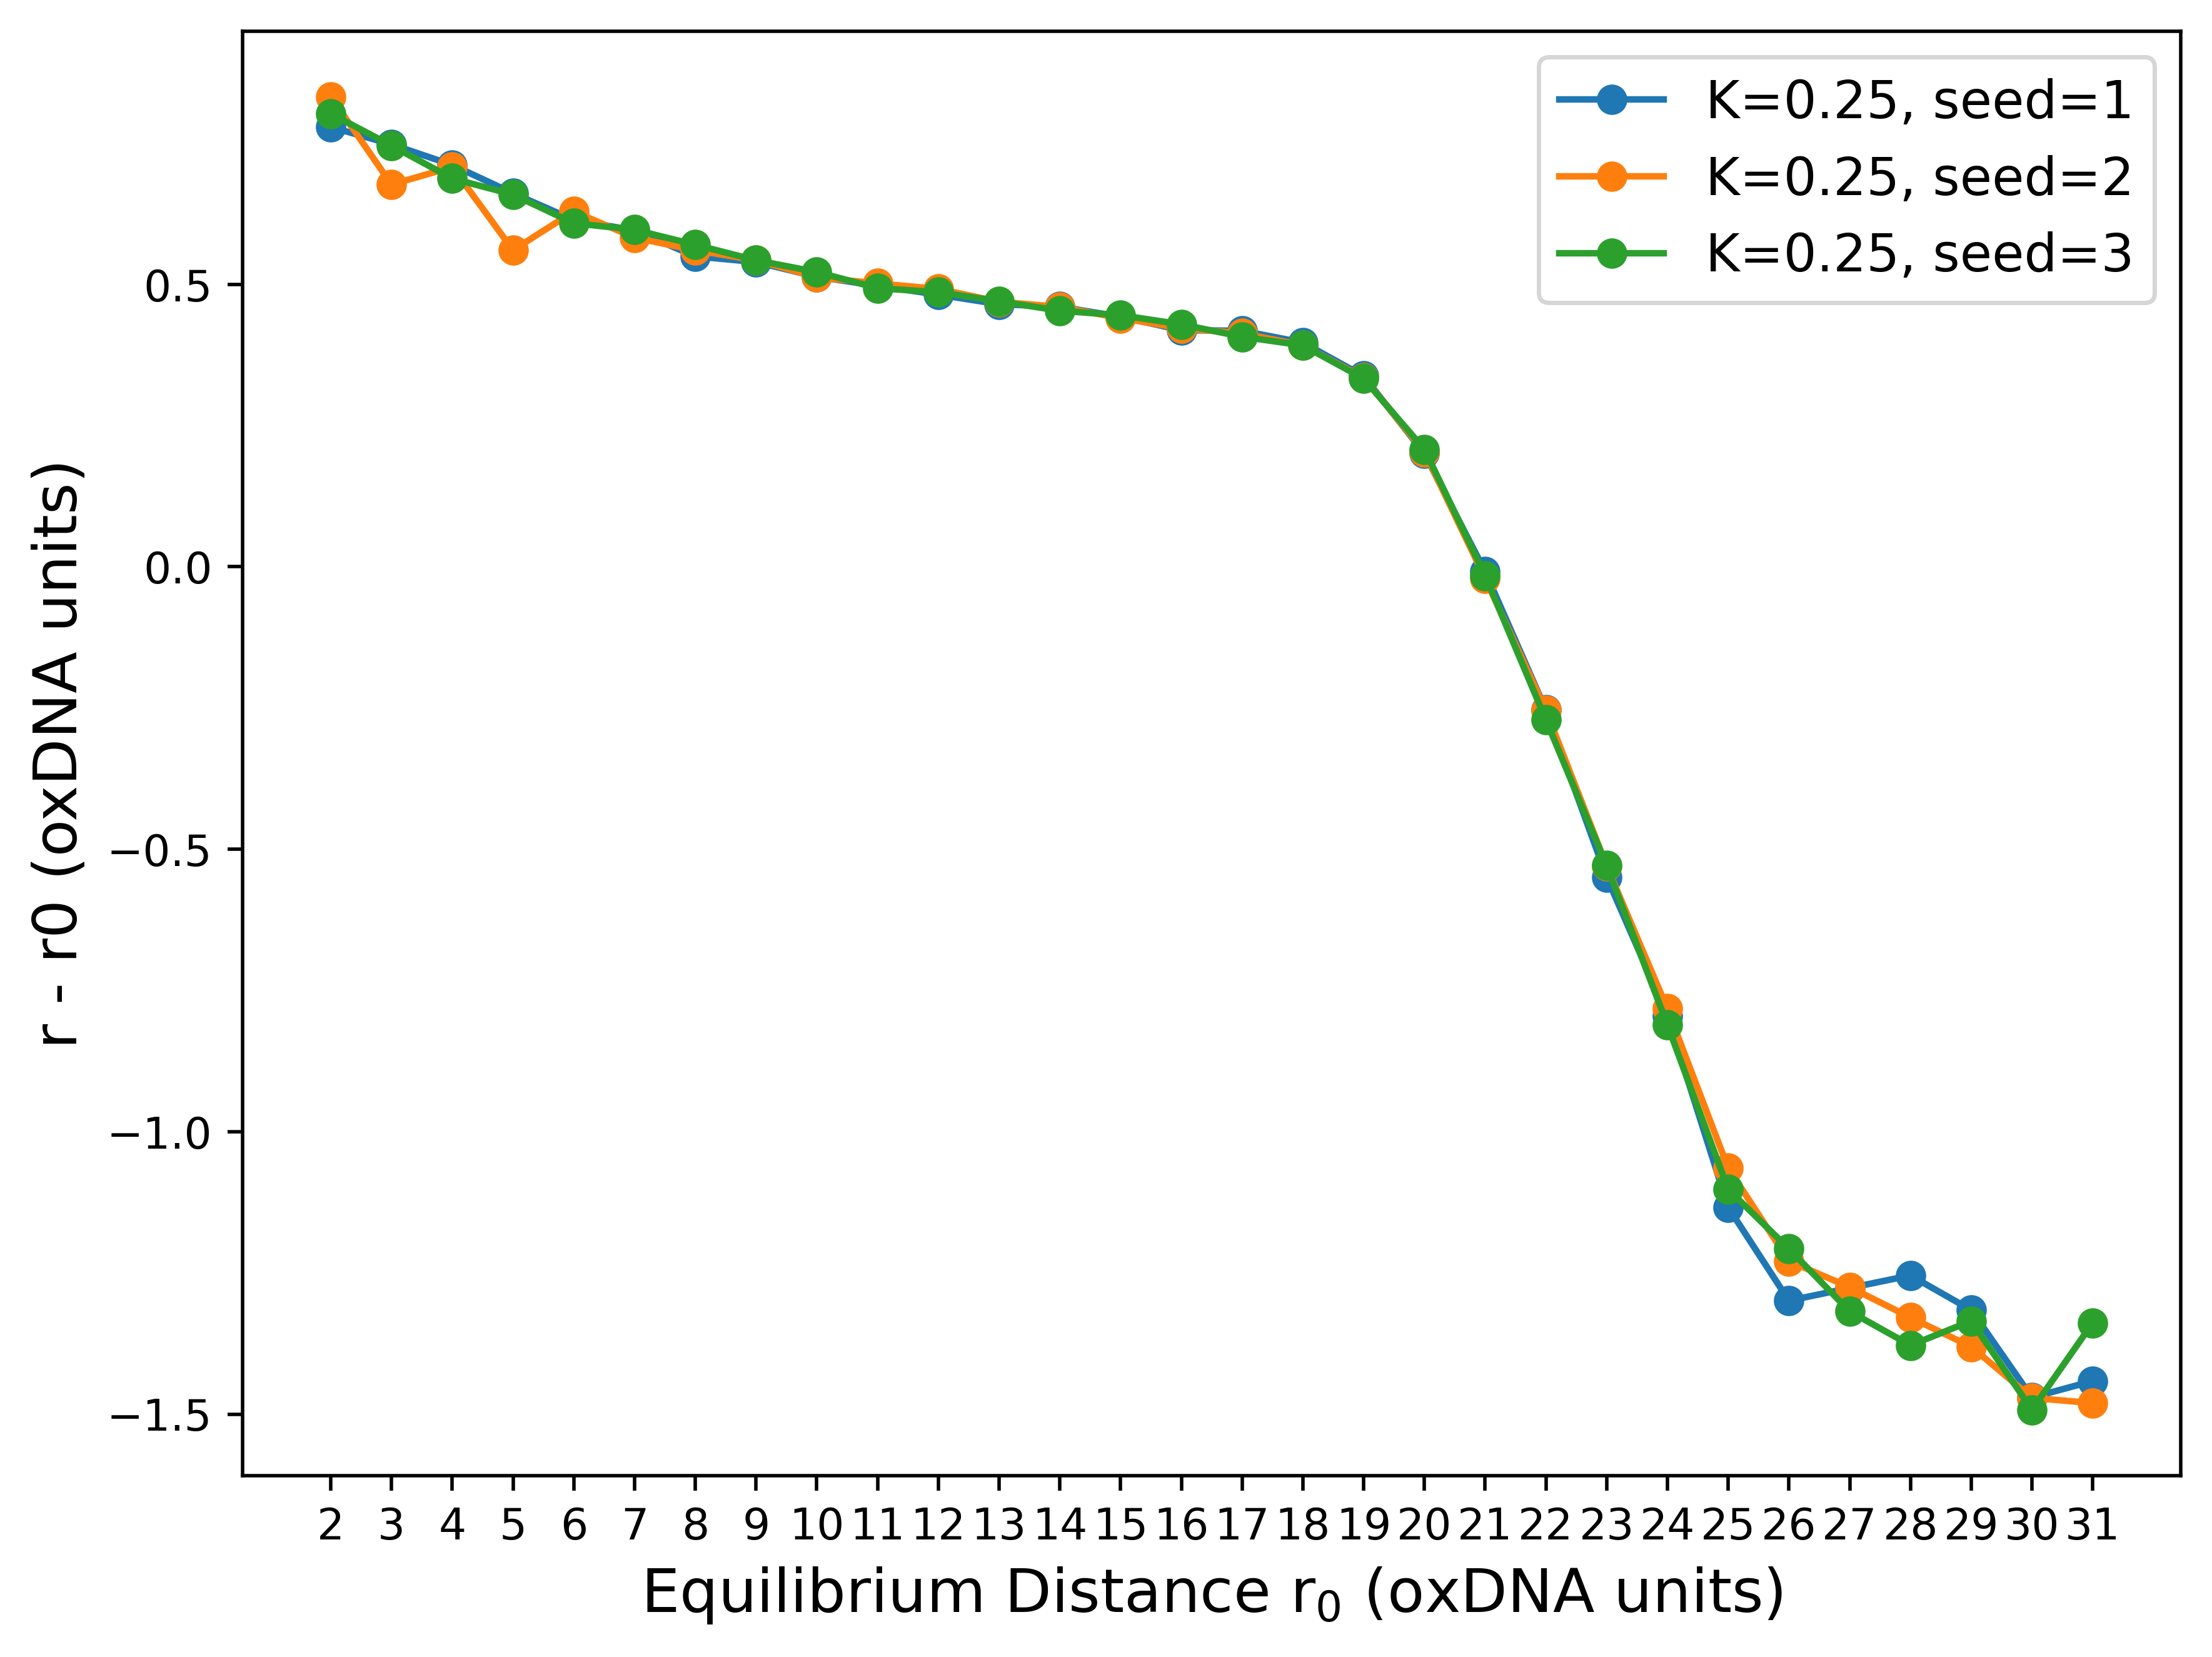

In [72]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        y = sub["dist mean"] - sub["r_0"]
        ax.plot(sub["r_0"], y, marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("r - r0 (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()

In [73]:
CUTOFF = 1.5e7  # 2,500,000

dfs_cfiltered = {}  # dfs_cfiltered[k][r0][seed] = cutoff-filtered df

for k, by_r0 in dfs.items():
    dfs_cfiltered[k] = {}
    for r0, by_seed in by_r0.items():
        dfs_cfiltered[k][r0] = {}
        for s, df in by_seed.items():
            dfs_cfiltered[k][r0][s] = df[df["step"] >= CUTOFF].reset_index(drop=True)

In [74]:
#### BASIC STATISTICS OF STEADY STATE REGION
import numpy as np
import pandas as pd

stats_data = []
for k, by_r0 in dfs_cfiltered.items():
    for r0 in r0_values:
        if r0 not in by_r0:
            continue
        for s, df in by_r0[r0].items():

            # signed force: +|F| if dist > r0, -|F| if dist < r0
            # np.sign gives -1, 0, +1; equality -> 0 (force becomes 0 at exact r0)
            signed_force = np.sign(df["dist"].to_numpy() - r0) * df["force_mag"].to_numpy()

            stats_data.append({
                "k": k,
                "r_0": float(r0),
                "seed": int(s),

                "F mean": signed_force.mean(),
                "F std": signed_force.std(ddof=0),

                "|F| mean": df["force_mag"].mean(),
                "|F| std": df["force_mag"].std(ddof=0),

                "dist mean": df["dist"].mean(),
                "dist std": df["dist"].std(ddof=0),
                "hbonds mean": df["hbond"].mean(),
            })

stats_df = pd.DataFrame(stats_data).sort_values(["k", "r_0", "seed"])
print(stats_df)

       k   r_0  seed    F mean     F std  |F| mean   |F| std  dist mean  \
0   0.25   2.0     1  0.191758  0.147704  0.204375  0.129688   2.767033   
1   0.25   2.0     2  0.205575  0.148402  0.216332  0.132228   2.822299   
2   0.25   2.0     3  0.188979  0.146673  0.201504  0.128926   2.755916   
3   0.25   3.0     1  0.190683  0.151793  0.205558  0.130946   3.762733   
4   0.25   3.0     2  0.158354  0.156078  0.183235  0.125942   3.633415   
..   ...   ...   ...       ...       ...       ...       ...        ...   
85  0.25  30.0     2 -0.368243  0.151705  0.368919  0.150054  28.527028   
86  0.25  30.0     3 -0.304044  0.154947  0.306588  0.149850  28.783826   
87  0.25  31.0     1 -0.331380  0.151878  0.332866  0.148593  29.674480   
88  0.25  31.0     2 -0.355532  0.151152  0.356333  0.149256  29.577871   
89  0.25  31.0     3 -0.319283  0.150699  0.321420  0.146085  29.722868   

    dist std  hbonds mean  
0   0.590818    82.895168  
1   0.593607    83.060105  
2   0.586691   

C:\Users\Tristan\AppData\Local\Temp\ipykernel_10112\2783019263.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=12)


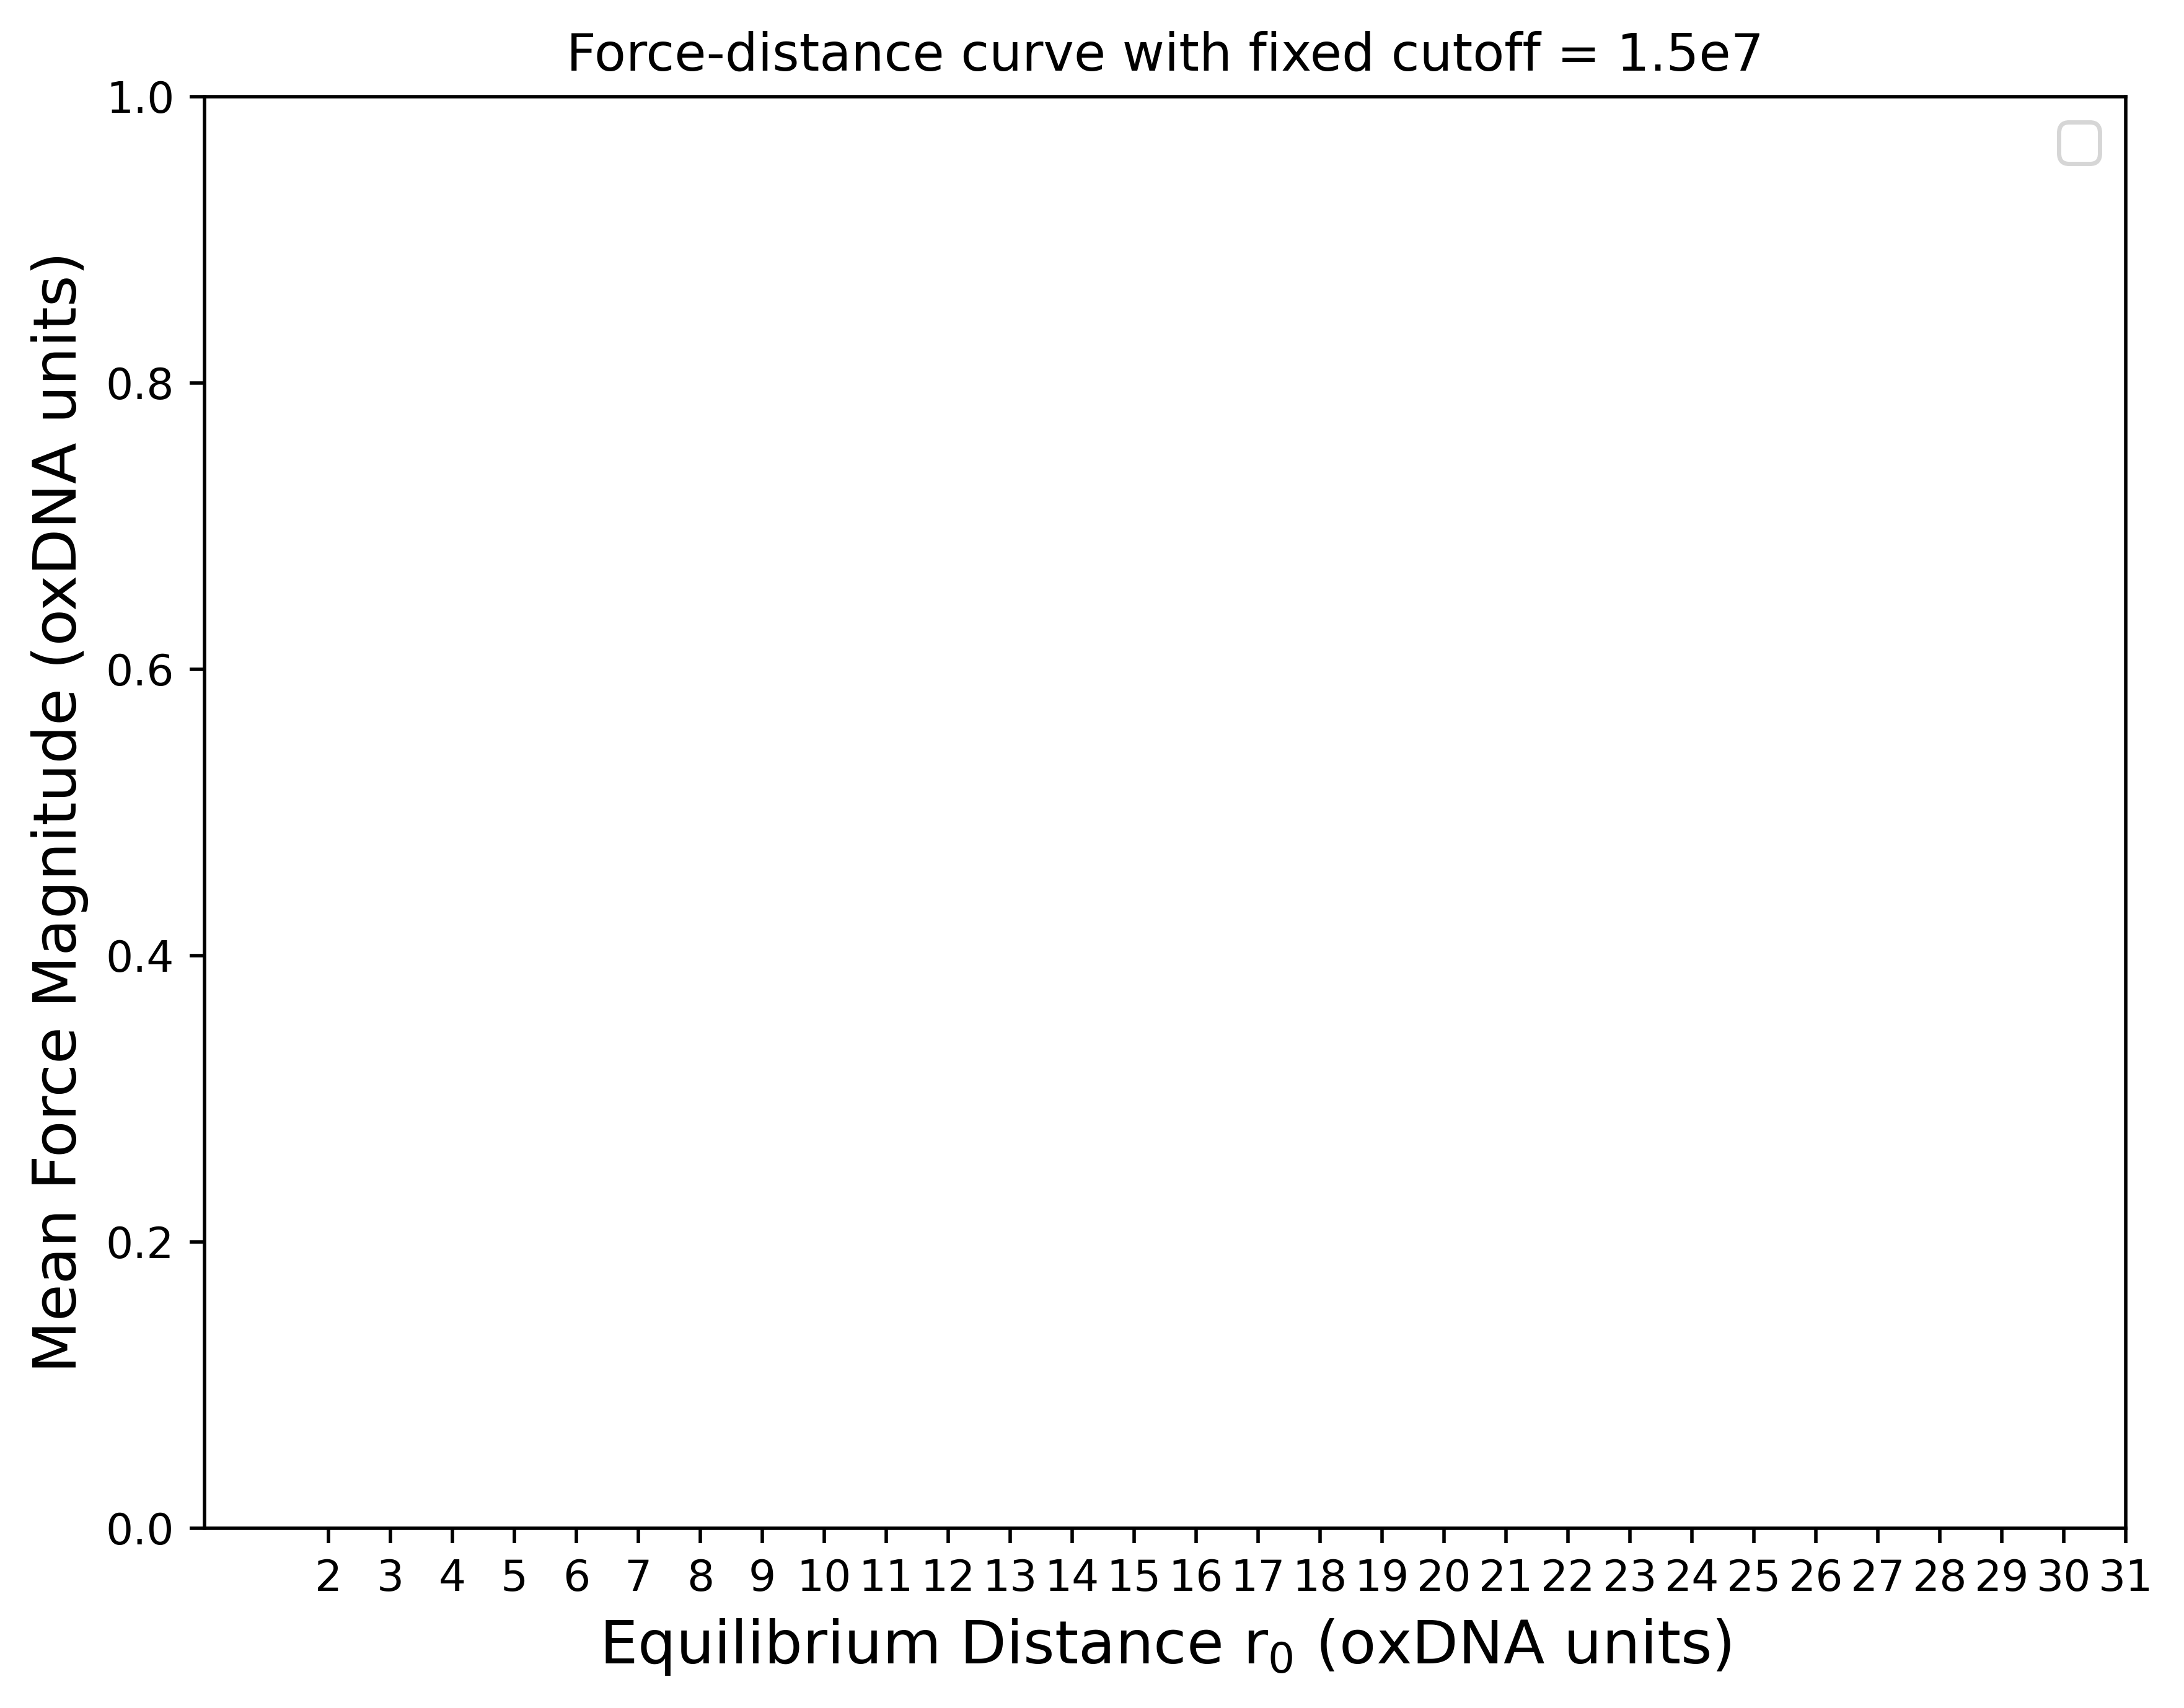

In [75]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        ax.plot(sub["r_0"], sub["|F| mean"], marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("Mean Force Magnitude (oxDNA units)", fontsize=14)
ax.set_title("Force-distance curve with fixed cutoff = 1.5e7")
ax.legend(fontsize=12)

plt.show()

C:\Users\Tristan\AppData\Local\Temp\ipykernel_10112\2041335325.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=12)


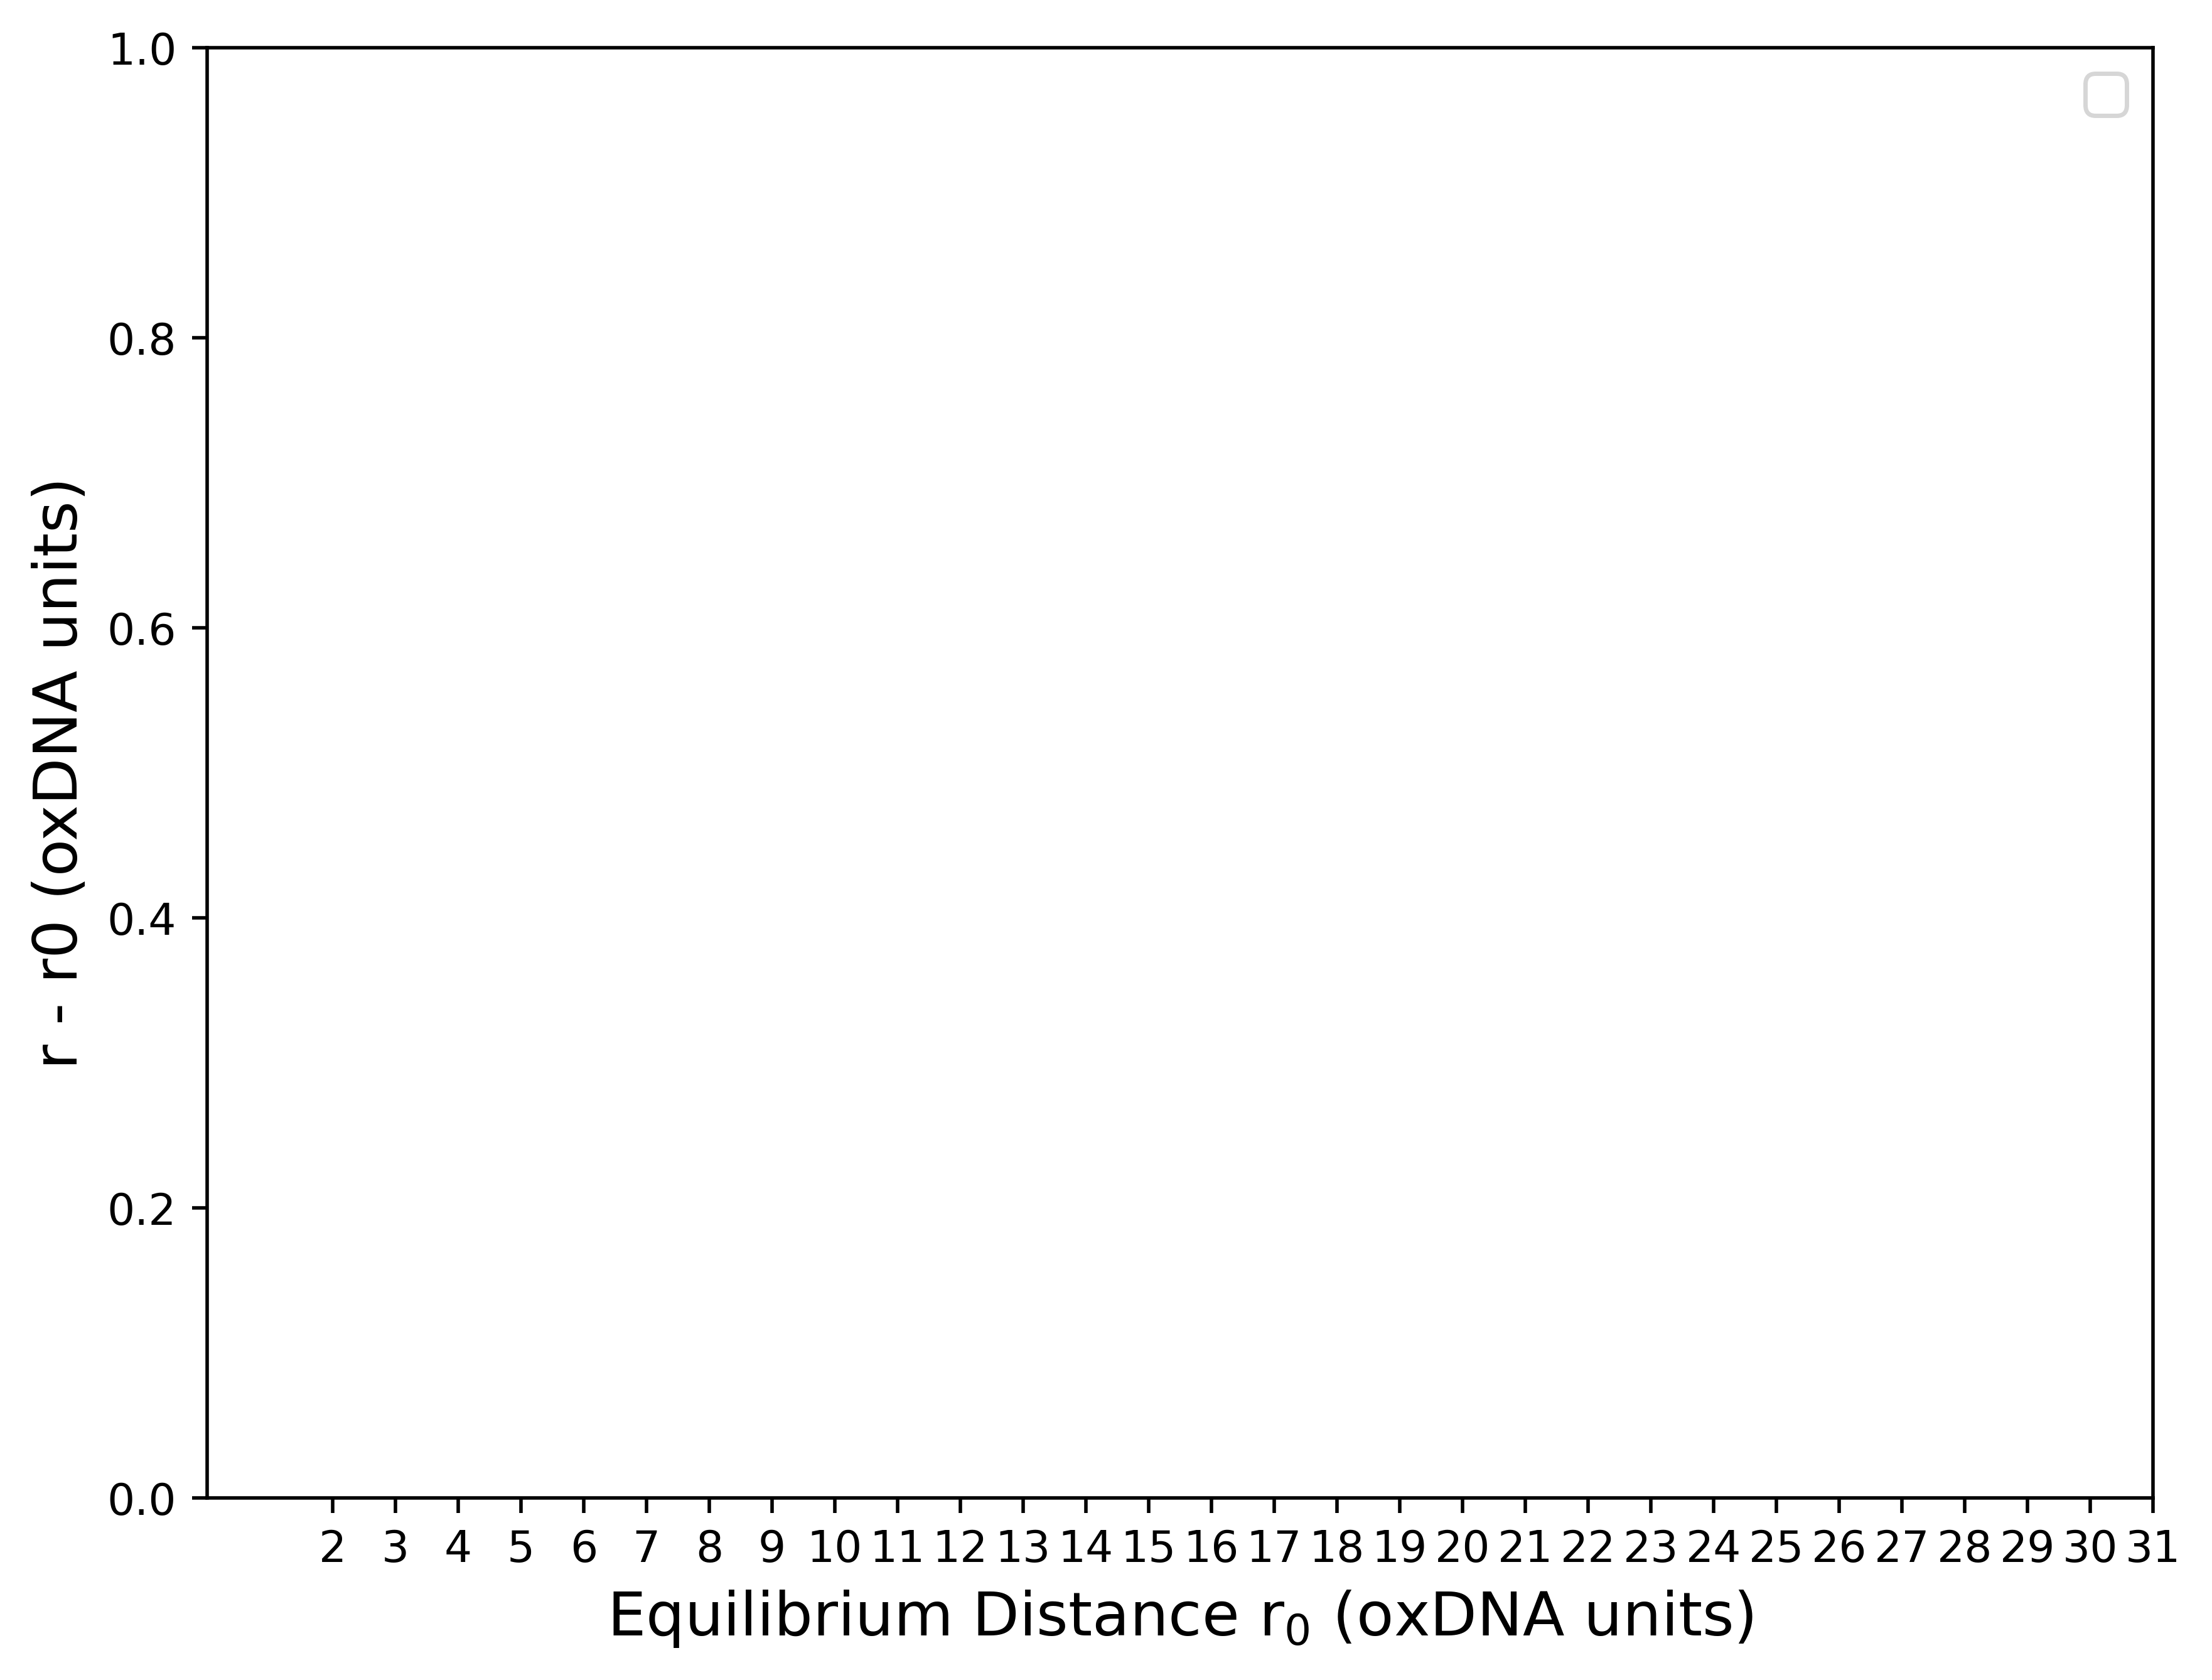

In [76]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,6), dpi=500)

for k, label in [(0.35, "K=0.35"), (0.45, "K=0.45")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("r_0")
        y = sub["dist mean"] - sub["r_0"]
        ax.plot(sub["r_0"], y, marker="o", label=f"{label}, seed={s}")
ax.set_xticks(r0_values)
ax.set_xlabel(r"Equilibrium Distance r$_0$ (oxDNA units)", fontsize=14)
ax.set_ylabel("r - r0 (oxDNA units)", fontsize=14)
ax.legend(fontsize=12)

plt.show()

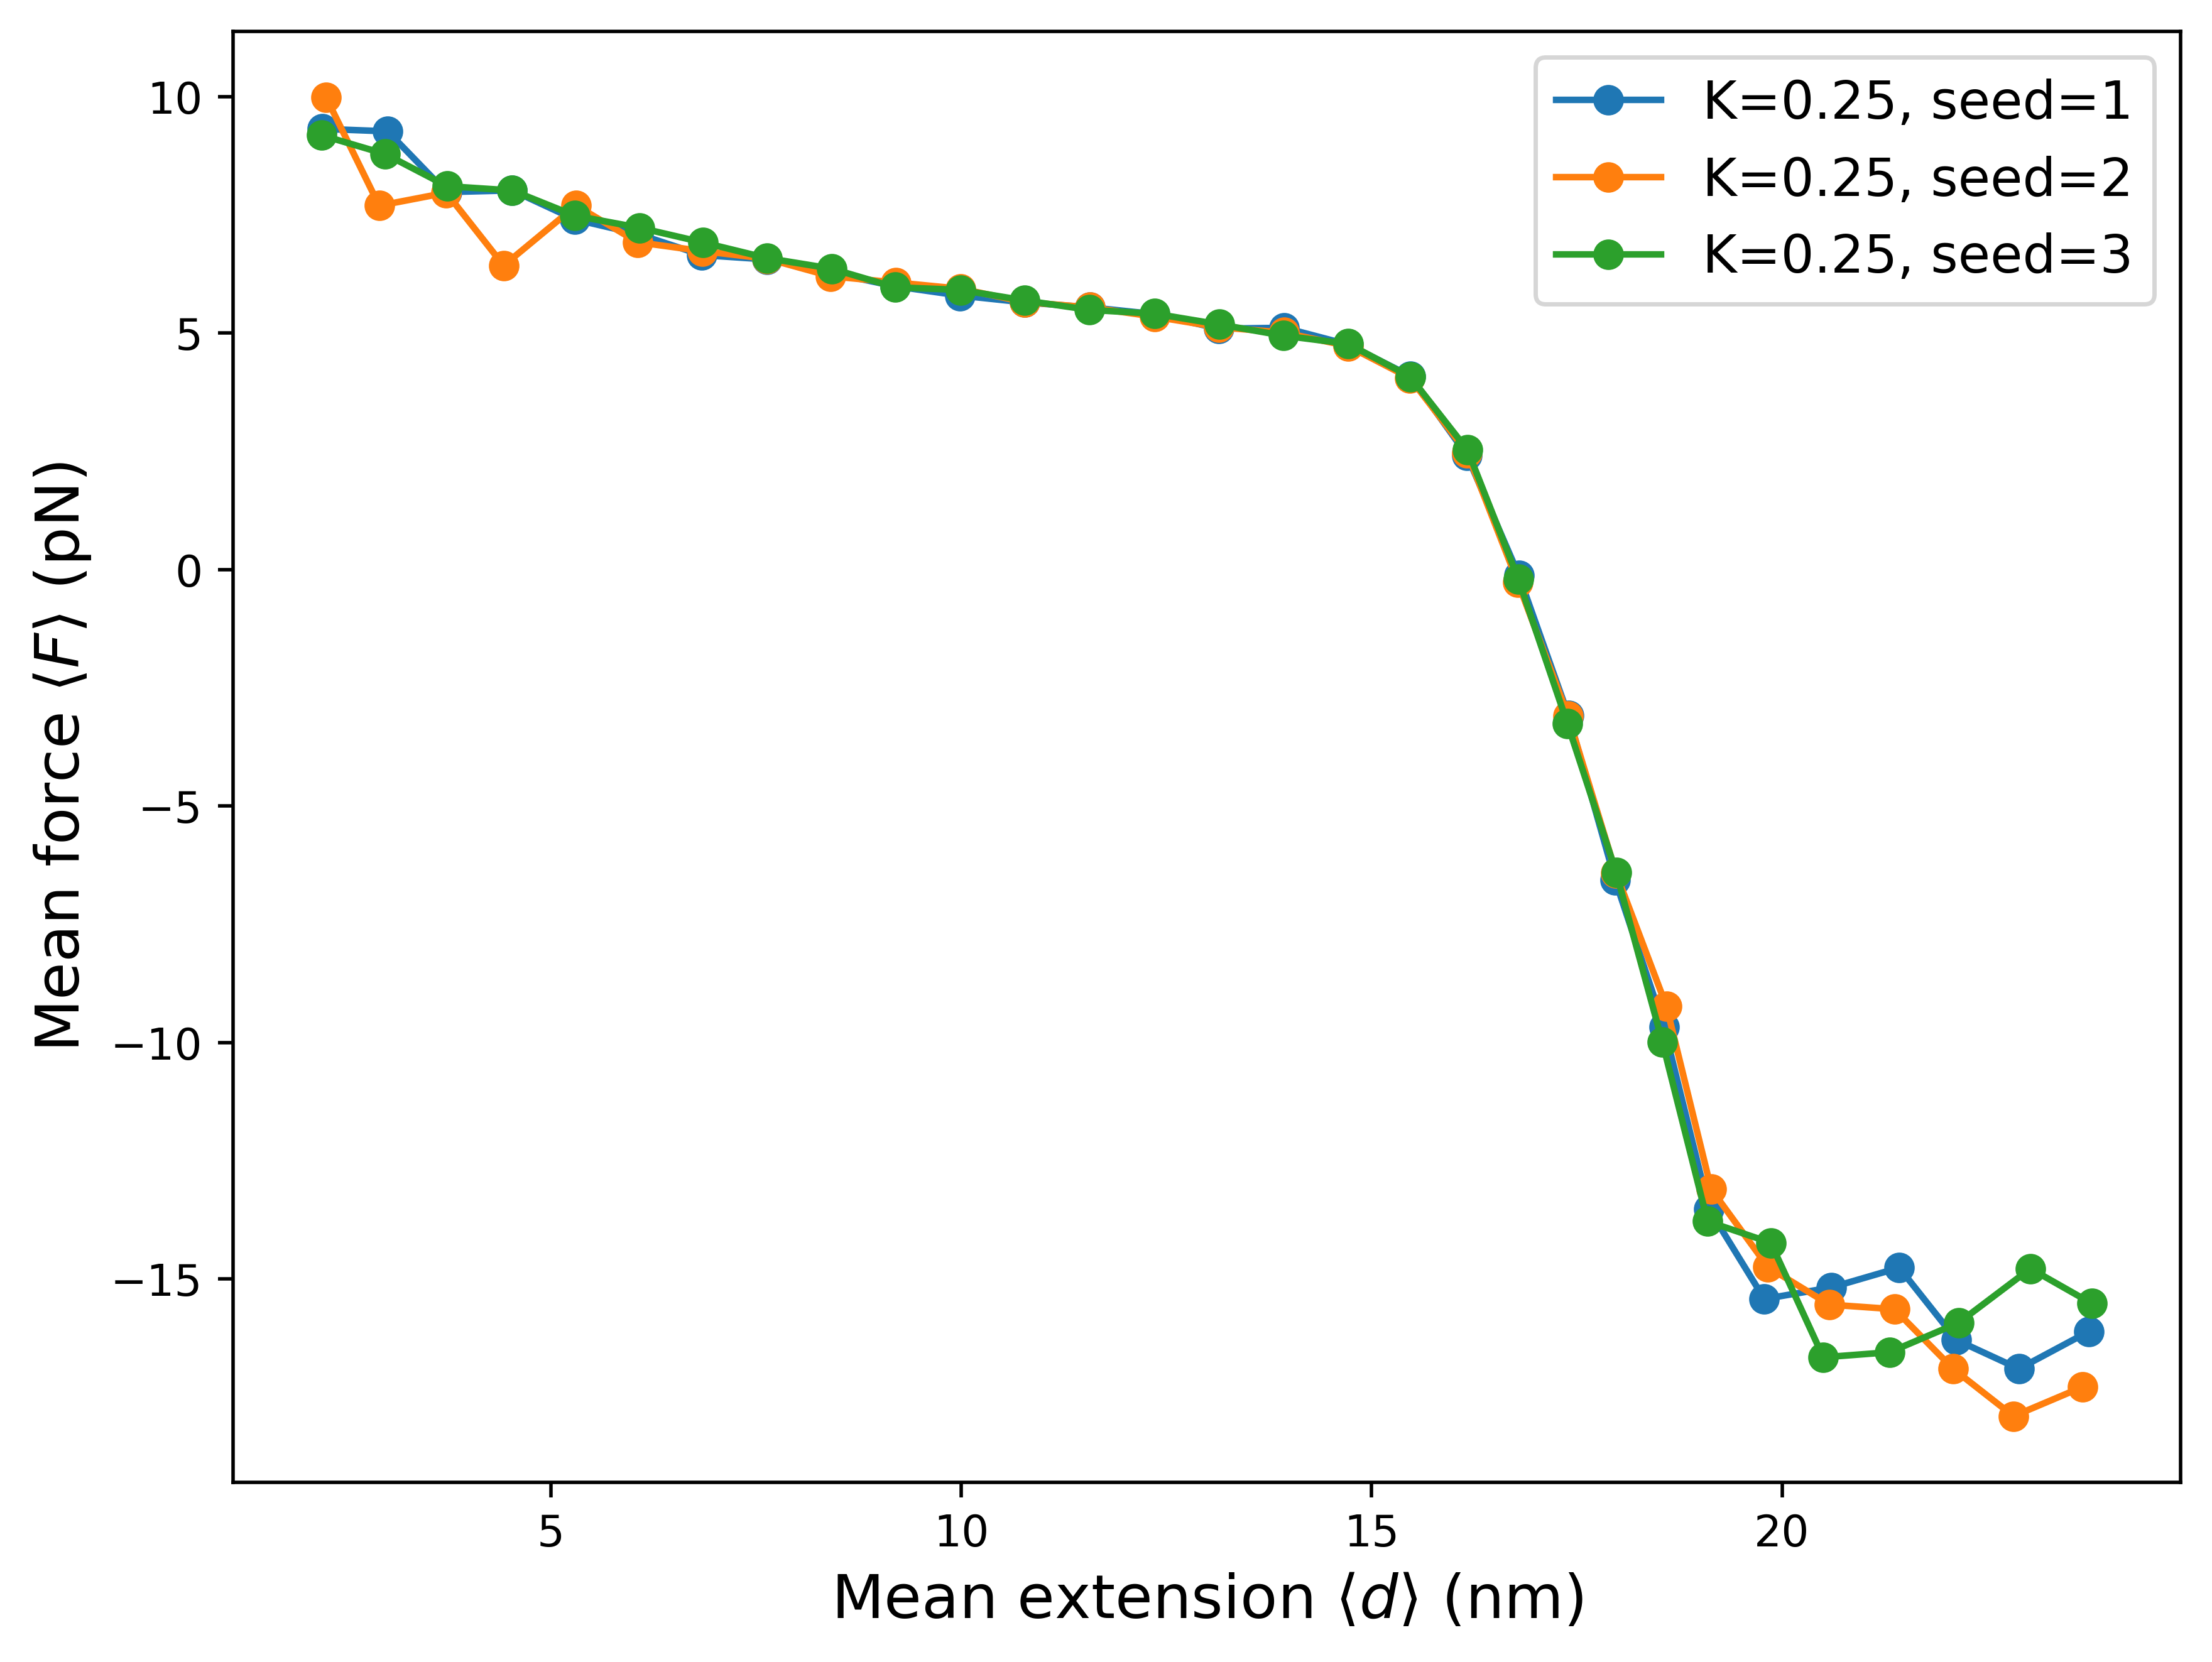

In [77]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6), dpi=500)

for k, label in [(0.25, "K=0.25")]:
    sub_k = stats_df[stats_df["k"] == k]
    for s in sorted(sub_k["seed"].unique()):
        sub = sub_k[sub_k["seed"] == s].sort_values("dist mean")
        ax.plot(0.8*sub["dist mean"], 48.6*sub["F mean"], marker="o", label=f"{label}, seed={s}")

ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)", fontsize=14)
ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)", fontsize=14)
ax.legend(fontsize=12)

plt.show()